In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt


In [2]:
df = pd.read_csv("Mall_Customers.csv")

In [3]:
df = pd.DataFrame(df)

In [4]:


df.shape

(200, 5)

In [5]:
df.head()


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB


In [7]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [8]:
print(df.columns)

Index(['CustomerID', 'Gender', 'Age', 'Annual Income (k$)',
       'Spending Score (1-100)'],
      dtype='str')


In [9]:
df = df.drop(columns=['CustomerID'])


In [10]:
df = df[['Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']]

income_labels = [f'{start}-{start + 10}' for start in range(0, 200, 10)]
df['Income_Group'] = pd.cut(
    df['Annual Income (k$)'],
    bins=range(0, 201, 10),
    labels=income_labels,
    include_lowest=True,
    right=False
)

df[['Annual Income (k$)', 'Income_Group']].head()

,Annual Income (k$),Income_Group
0,15,10-20
1,15,10-20
2,16,10-20
3,16,10-20
4,17,10-20


In [11]:
df['Income_Group'].value_counts()

Income_Group
70-80      38
60-70      32
40-50      26
50-60      20
20-30      18
30-40      16
80-90      16
10-20      12
90-100      8
100-110     6
120-130     4
110-120     2
130-140     2
0-10        0
140-150     0
150-160     0
160-170     0
170-180     0
180-190     0
190-200     0
Name: count, dtype: int64

In [12]:
spending_labels = [f'{start}-{start + 10}' for start in range(0, 100, 10)]
df['Spending_Group'] = pd.cut(
    df['Spending Score (1-100)'],
    bins=range(0, 101, 10),
    labels=spending_labels,
    include_lowest=True,
    right=False
)

remove_groups = ['90-100', '100-110', '110-120', '120-130', '130-140', '140-150', '150-160', '160-170', '170-180', '180-190', '190-200']
df = df[~df['Spending_Group'].isin(remove_groups)].copy()

df[['Spending Score (1-100)', 'Spending_Group']].head()

,Spending Score (1-100),Spending_Group
0,39,30-40
1,81,80-90
2,6,0-10
3,77,70-80
4,40,40-50


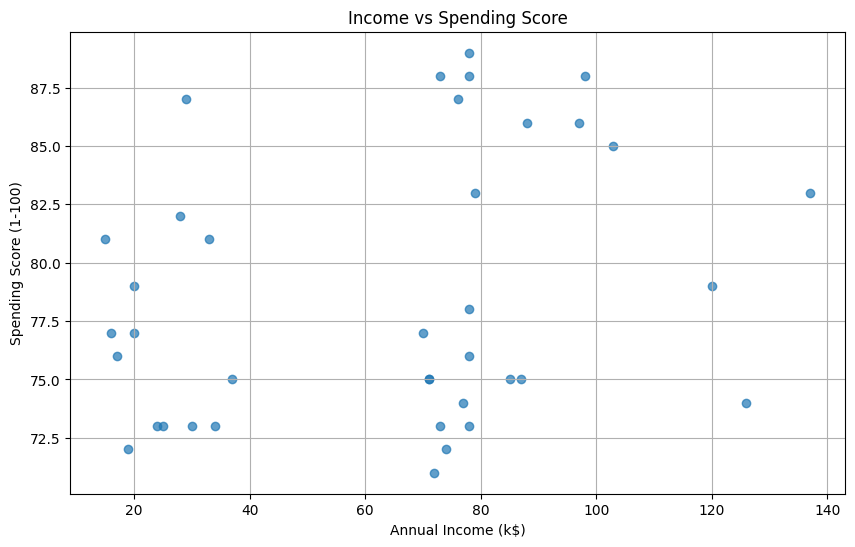

In [ ]:
df = df[df['Spending Score (1-100)'] > 70].copy()
df.to_csv('high_spenders.csv', index=False)

plt.figure(figsize=(10, 6))
plt.scatter(df['Annual Income (k$)'], df['Spending Score (1-100)'], alpha=0.7)
plt.title('Income vs Spending Score')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.grid(True)
plt.show()
